In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv("../data/data_set.csv")
print("data read successfully")

data read successfully


In [3]:
features= ["ambient","coolant","motor_speed","torque","i_d","i_q","u_d","u_q"]
target = "stator_winding" 

In [4]:
X = df[features]
y = df[target]
groups = df["profile_id"]

In [5]:
from sklearn.model_selection import GroupShuffleSplit 
gss = GroupShuffleSplit(n_splits=1,test_size=0.2 ,random_state=42)
train_idx , test_idx = next(gss.split(X,y,groups=groups))

In [6]:
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [7]:
train_profiles = df.iloc[train_idx]["profile_id"].unique()
test_profiles  = df.iloc[test_idx]["profile_id"].unique()
print("Training profiles" , len(train_profiles) ,"\nTest profiles" , len(test_profiles))


Training profiles 55 
Test profiles 14


In [8]:
overlap = set(train_profiles)&set(test_profiles)
print("overlapping profiles" , overlap)

overlapping profiles set()


In [9]:
from sklearn.linear_model import LinearRegression   
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 1.3 , 0.69,-0. ,...,-0.11,-0.02,-0.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['ambient','coolant','motor_speed',...,'i_q','u_d','u_q']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-9.109
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [10]:
y_pred = model.predict(X_test)

In [11]:
from sklearn.metrics import mean_absolute_error , mean_squared_error, r2_score

mae = mean_absolute_error(y_test , y_pred )

rmse = np.sqrt(mean_squared_error(y_test, y_pred ))
r2 = r2_score(y_test, y_pred)
print("MAE" , mae , "\nRMSE" , rmse ,"\nR2 score " , r2)

MAE 11.148706373271926 
RMSE 15.071123949403702 
R2 score  0.7532347818918649


In [12]:
coefficients = pd.DataFrame({"Feature":features,"Coefficient":model.coef_})
coefficients

,Feature,Coefficient
0,ambient,1.296295
1,coolant,0.691631
2,motor_speed,-0.000043
3,torque,0.149839
4,i_d,-0.270296
5,i_q,-0.106968
6,u_d,-0.016353
7,u_q,-0.020338


In [ ]:
from sklearn.dummy import DummyRegressor

dummy_model = DummyRegressor(strategy="mean")

dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_test)

In [14]:
dummy_mae = mean_absolute_error(y_test , dummy_pred)

dummy_rmse = np.sqrt(mean_squared_error(y_test , dummy_pred))

dummy_r2 = r2_score(y_test , dummy_pred)

In [16]:
print ("Print dummy regressor results" , 
       "\nmean squared error:" , dummy_mae , 
       "\nroot mean squared error:" , dummy_rmse , 
       "\nr2 score:" , dummy_r2)

Print dummy regressor results 
mean squared error: 25.903932614539286 
root mean squared error: 30.34548952565187 
r2 score: -0.000416757231449294


In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor 
boost_model = HistGradientBoostingRegressor(
    max_iter=100 ,
    learning_rate = 0.1,
    max_leaf_nodes=31,
    random_state=42 )
boost_model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [19]:
boost_pred = boost_model.predict(X_test)

In [20]:
boost_mae = mean_absolute_error(y_test , boost_pred)
boost_rmse = np.sqrt(mean_squared_error(y_test , boost_pred))
boost_r2 = r2_score(y_test , boost_pred)

print("Results of HistGradientBoosting regression",  
      "\nmae:",boost_mae,
      "\nrmse:",boost_rmse,
      "\nr2:",boost_r2)

Results of HistGradientBoosting regression 
mae: 10.25871470068254 
rmse: 14.134849638975634 
r2: 0.782942374354885


In [22]:
results = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        "MAE (°C)": dummy_mae,
        "RMSE (°C)": dummy_rmse,
        "R²": dummy_r2
    },
    {
        "Model": "Linear Regression",
        "MAE (°C)": mae,
        "RMSE (°C)": rmse,
        "R²": r2
    },
    {
        "Model": "HistGradientBoosting",
        "MAE (°C)": boost_mae,
        "RMSE (°C)": boost_rmse,
        "R²": boost_r2
    }
])

display(results.round(3))

,Model,MAE (°C),RMSE (°C),R²
0,Dummy Regressor,25.904,30.345,-0.000
1,Linear Regression,11.149,15.071,0.753
2,HistGradientBoosting,10.259,14.135,0.783


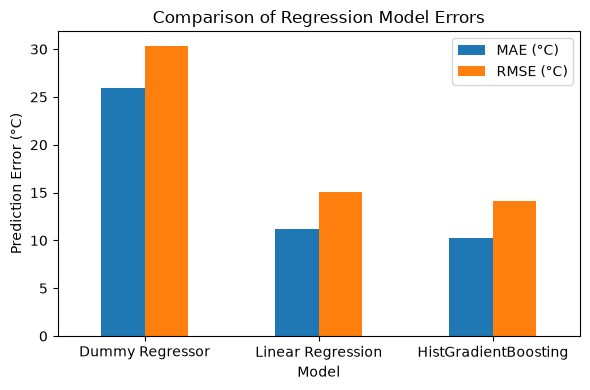

In [30]:
import matplotlib.pyplot as plt

error_results = results.set_index("Model")[
    ["MAE (°C)", "RMSE (°C)"]
]

ax = error_results.plot(
    kind="bar",
    figsize=(6, 4)
)

ax.set_title("Comparison of Regression Model Errors")
ax.set_xlabel("Model")
ax.set_ylabel("Prediction Error (°C)")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "model_error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

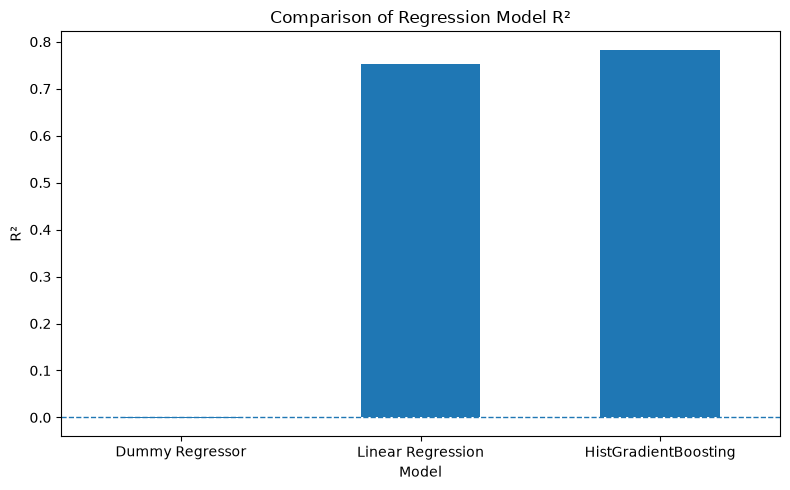

In [31]:
ax = results.set_index("Model")["R²"].plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_title("Comparison of Regression Model R²")
ax.set_xlabel("Model")
ax.set_ylabel("R²")

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "model_r2_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

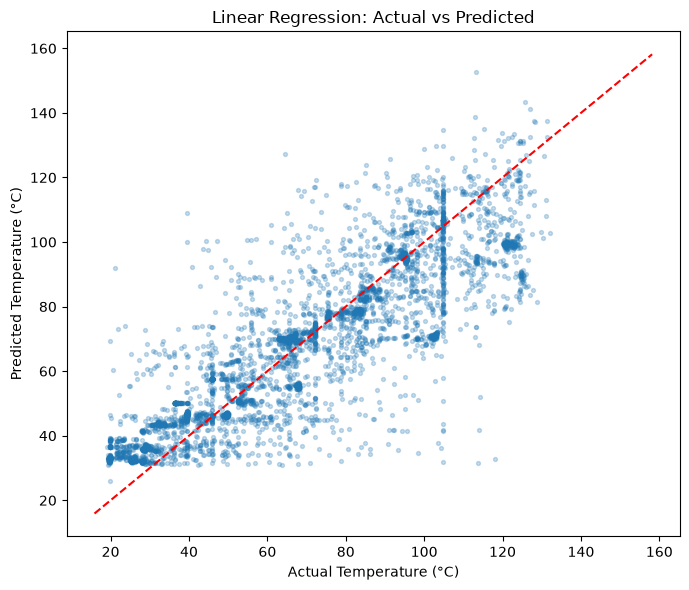

In [32]:
plot_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Linear Regression": np.asarray(y_pred),
    "HistGradientBoosting": np.asarray(boost_pred)
})

plot_sample = plot_df.sample(
    n=min(5000, len(plot_df)),
    random_state=42
)

lower = min(
    plot_df["Actual"].min(),
    plot_df["Linear Regression"].min(),
    plot_df["HistGradientBoosting"].min()
)

upper = max(
    plot_df["Actual"].max(),
    plot_df["Linear Regression"].max(),
    plot_df["HistGradientBoosting"].max()
)

plt.figure(figsize=(7, 6))

plt.scatter(
    plot_sample["Actual"],
    plot_sample["Linear Regression"],
    alpha=0.25,
    s=8
)

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--"
)

plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.title("Linear Regression: Actual vs Predicted")

plt.tight_layout()

plt.savefig(
    "linear_regression_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
results.to_csv(
    "model_comparison_results.csv",
    index=False
)